In [ ]:
import numpy as np
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

y_true = np.array([1]*10 + [0]*90)
y_pred = np.array([1]*6 + [0]*4 + [1]*9 + [0]*81)

print(confusion_matrix(y_true, y_pred))
print("accuratezza:", accuracy_score(y_true, y_pred))
print("precisione: ", precision_score(y_true, y_pred))
print("recall:     ", recall_score(y_true, y_pred))
print("F1:         ", f1_score(y_true, y_pred))

[[81  9]
 [ 4  6]]
accuratezza: 0.87
precisione:  0.4
recall:      0.6
F1:          0.48


In [ ]:
#sempre sano
y_zero = np.zeros(100, dtype=int)

print(confusion_matrix(y_true, y_zero))
print("accuratezza:", accuracy_score(y_true, y_zero))
print("precisione: ", precision_score(y_true, y_zero, zero_division=0))
print("recall:     ", recall_score(y_true, y_zero))

[[90  0]
 [10  0]]
accuratezza: 0.9
precisione:  0.0
recall:      0.0


In [ ]:
scores = np.array([0.9, 0.8, 0.6, 0.4,   0.7, 0.5, 0.3, 0.2, 0.2, 0.1])
y      = np.array([1,   1,   1,   1,     0,   0,   0,   0,   0,   0  ])
# primi 4 = malati, ultimi 6 = sani

for t in [0.75, 0.5, 0.35, 0.15]:
    pred = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"soglia {t}:  TP={tp} FN={fn} FP={fp} TN={tn} | "
          f"recall={tp/(tp+fn):.2f}  falsi allarmi sui sani={fp/(fp+tn):.2f}")

soglia 0.75:  TP=2 FN=2 FP=0 TN=6 | recall=0.50  falsi allarmi sui sani=0.00
soglia 0.5:  TP=3 FN=1 FP=2 TN=4 | recall=0.75  falsi allarmi sui sani=0.33
soglia 0.35:  TP=4 FN=0 FP=2 TN=4 | recall=1.00  falsi allarmi sui sani=0.33
soglia 0.15:  TP=4 FN=0 FP=5 TN=1 | recall=1.00  falsi allarmi sui sani=0.83


soglia inf: falsi allarmi=0.00  recall=0.00
soglia 0.90: falsi allarmi=0.00  recall=0.25
soglia 0.80: falsi allarmi=0.00  recall=0.50
soglia 0.70: falsi allarmi=0.17  recall=0.50
soglia 0.60: falsi allarmi=0.17  recall=0.75
soglia 0.50: falsi allarmi=0.33  recall=0.75
soglia 0.40: falsi allarmi=0.33  recall=1.00
soglia 0.30: falsi allarmi=0.50  recall=1.00
soglia 0.20: falsi allarmi=0.83  recall=1.00
soglia 0.10: falsi allarmi=1.00  recall=1.00


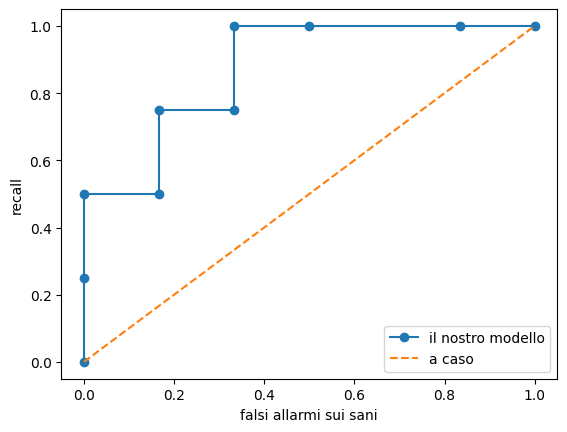

AUC: 0.875


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thr = roc_curve(y, scores)
for f, r, t in zip(fpr, tpr, thr):
    print(f"soglia {t:.2f}: falsi allarmi={f:.2f}  recall={r:.2f}")

plt.plot(fpr, tpr, marker="o", label="il nostro modello")
plt.plot([0, 1], [0, 1], "--", label="a caso")
plt.xlabel("falsi allarmi sui sani")
plt.ylabel("recall")
plt.legend()
plt.show()

print("AUC:", roc_auc_score(y, scores))

In [ ]:
scores_B = 0.5 + scores / 2

for nome, s in [("A", scores), ("B", scores_B)]:
    pred = (s >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"modello {nome}: soglia 0.5 -> recall={tp/(tp+fn):.2f}, "
          f"falsi allarmi={fp/(fp+tn):.2f}, AUC={roc_auc_score(y, s):.3f}")

modello A: soglia 0.5 -> recall=0.75, falsi allarmi=0.33, AUC=0.875
modello B: soglia 0.5 -> recall=1.00, falsi allarmi=1.00, AUC=0.875
